<a href="https://colab.research.google.com/github/fernandyan/MyGoogleColab/blob/main/fernand_flask.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# import

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score

from sklearn.preprocessing import LabelEncoder, OneHotEncoder, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, minmax_scale, OrdinalEncoder, MinMaxScaler, Normalizer
from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay, f1_score, precision_score, recall_score
from sklearn.pipeline import Pipeline

from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression

# 1 - social midia

In [15]:
data = pd.read_csv("/content/social_media_screentime_mental_health_2026.csv")
data = data.drop('participant_id', axis=1)
data

,age,gender,occupation,region,most_used_platform,platforms_used_count,daily_screen_hours,daily_notifications,night_time_use,minutes_to_first_check_after_waking,...,life_satisfaction_1to10,loneliness_1to10,self_esteem_1to10,fomo_1to10,social_comparison_1to10,physical_activity_days_per_week,uses_screen_time_limits,attempted_digital_detox,seeks_mental_health_support,wellbeing_band
0,33,Male,Student,Latin America,TikTok,8,3.2,172,Never,25,...,9,6,4,6,8,4,No,No,No,At-risk
1,23,Female,Full-time employed,Oceania,Instagram,8,4.5,38,Often,26,...,7,5,8,5,8,4,No,"Yes, failed",Yes,At-risk
2,56,Female,Full-time employed,Africa,Instagram,1,5.3,74,Every night,12,...,8,7,3,2,3,5,No,No,No,Moderate
3,13,Male,Student,Europe,YouTube,4,3.4,49,Sometimes,21,...,10,6,6,1,5,4,No,"Yes, failed",Yes,Moderate
4,36,Female,Student,Asia,LinkedIn,5,5.8,227,Never,19,...,4,6,8,7,9,3,Yes,"Yes, succeeded",No,Moderate
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6995,30,Male,Part-time employed,Europe,Snapchat,4,3.6,74,Never,7,...,4,4,6,3,10,2,Yes,No,No,Good
6996,28,Male,Self-employed,North America,Facebook,3,5.0,104,Every night,48,...,8,1,7,6,7,1,No,"Yes, failed",No,Moderate
6997,26,Prefer not to say,Unemployed,Oceania,LinkedIn,3,1.2,25,Never,6,...,9,4,5,1,6,3,No,No,No,Good
6998,22,Female,Student,Europe,Snapchat,4,3.6,182,Sometimes,12,...,5,7,4,1,6,2,No,"Yes, failed",No,Good


In [16]:
data.describe()

,age,platforms_used_count,daily_screen_hours,daily_notifications,minutes_to_first_check_after_waking,avg_sleep_hours,anxiety_score_0to27,low_mood_score_0to27,life_satisfaction_1to10,loneliness_1to10,self_esteem_1to10,fomo_1to10,social_comparison_1to10,physical_activity_days_per_week
count,7000.000000,7000.000000,7000.000000,7000.000000,7000.000000,6895.000000,7000.000000,7000.000000,7000.000000,7000.000000,7000.000000,7000.000000,7000.000000,7000.000000
mean,29.246571,3.494571,3.304971,61.528286,20.008286,6.964989,11.378000,3.845714,6.955857,4.679286,6.006857,4.641857,5.323286,2.804143
std,9.569132,1.763637,1.881350,54.879070,13.976229,0.870575,4.777726,3.534197,1.614486,2.094803,1.886767,2.157439,2.090788,1.288418
min,13.000000,1.000000,0.200000,5.000000,0.000000,3.800000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,22.000000,2.000000,1.900000,24.000000,10.000000,6.400000,8.000000,0.000000,6.000000,3.000000,5.000000,3.000000,4.000000,2.000000
50%,29.000000,3.000000,3.000000,45.500000,17.000000,7.000000,11.000000,3.000000,7.000000,5.000000,6.000000,5.000000,5.000000,3.000000
75%,36.000000,5.000000,4.300000,83.000000,27.000000,7.600000,14.000000,6.000000,8.000000,6.000000,7.000000,6.000000,7.000000,4.000000
max,71.000000,8.000000,14.000000,400.000000,111.000000,10.000000,27.000000,19.000000,10.000000,10.000000,10.000000,10.000000,10.000000,7.000000


In [17]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7000 entries, 0 to 6999
Data columns (total 24 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   age                                  7000 non-null   int64  
 1   gender                               6930 non-null   object 
 2   occupation                           7000 non-null   object 
 3   region                               7000 non-null   object 
 4   most_used_platform                   7000 non-null   object 
 5   platforms_used_count                 7000 non-null   int64  
 6   daily_screen_hours                   7000 non-null   float64
 7   daily_notifications                  7000 non-null   int64  
 8   night_time_use                       7000 non-null   object 
 9   minutes_to_first_check_after_waking  7000 non-null   int64  
 10  primary_purpose                      7000 non-null   object 
 11  avg_sleep_hours               

In [18]:
data.value_counts('most_used_platform')

,count
most_used_platform,
TikTok,1733
Instagram,1703
YouTube,1264
X/Twitter,585
Facebook,522
Snapchat,508
Reddit,411
LinkedIn,274


In [19]:
data.value_counts('age')

,count
age,
13,439
29,316
30,306
31,288
26,267
32,256
28,255
27,251
25,250


In [20]:
data.value_counts('region')

,count
region,
Asia,1959
North America,1842
Europe,1834
Latin America,670
Africa,425
Oceania,270


In [21]:
data.value_counts('social_comparison_1to10')

,count
social_comparison_1to10,
6,1232
5,1214
4,1074
7,969
3,798
8,625
2,378
9,287
1,249


In [22]:
data['most_used_platform'].unique(), data['gender'].unique(), data['region'].unique(), data['region'].unique(), data['night_time_use'].unique(), data['social_comparison_1to10'].unique()

(array(['TikTok', 'Instagram', 'YouTube', 'LinkedIn', 'X/Twitter',
        'Facebook', 'Snapchat', 'Reddit'], dtype=object),
 array(['Male', 'Female', 'Prefer not to say', 'Non-binary', nan],
       dtype=object),
 array(['Latin America', 'Oceania', 'Africa', 'Europe', 'Asia',
        'North America'], dtype=object),
 array(['Latin America', 'Oceania', 'Africa', 'Europe', 'Asia',
        'North America'], dtype=object),
 array(['Never', 'Often', 'Every night', 'Sometimes'], dtype=object),
 array([ 8,  3,  5,  9,  7, 10,  4,  6,  1,  2]))

In [23]:
data.isna().sum()

,0
age,0
gender,70
occupation,0
region,0
most_used_platform,0
platforms_used_count,0
daily_screen_hours,0
daily_notifications,0
night_time_use,0
minutes_to_first_check_after_waking,0


In [24]:
data.value_counts('most_used_platform')

,count
most_used_platform,
TikTok,1733
Instagram,1703
YouTube,1264
X/Twitter,585
Facebook,522
Snapchat,508
Reddit,411
LinkedIn,274


{'whiskers': [<matplotlib.lines.Line2D at 0x7db864e56ad0>,
 'caps': [<matplotlib.lines.Line2D at 0x7db864e56d50>,
 'boxes': [<matplotlib.lines.Line2D at 0x7db86518e850>],
 'medians': [<matplotlib.lines.Line2D at 0x7db864e56e90>],
 'fliers': [<matplotlib.lines.Line2D at 0x7db864e56fd0>],
 'means': []}

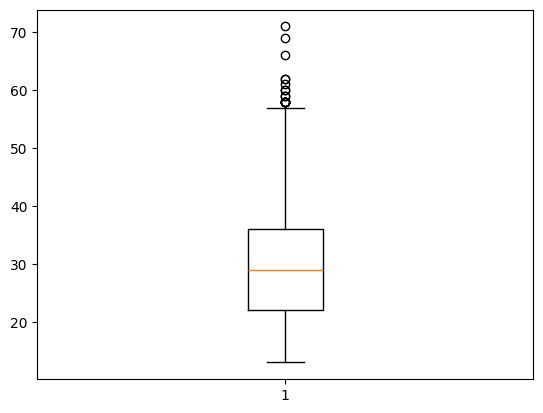

In [25]:
plt.boxplot(data['age'])

(array([ 191.,  569., 1198., 1095., 1718., 1263.,  448.,  359.,  121.,
          38.]),
 array([ 0. ,  2.7,  5.4,  8.1, 10.8, 13.5, 16.2, 18.9, 21.6, 24.3, 27. ]),
 <BarContainer object of 10 artists>)

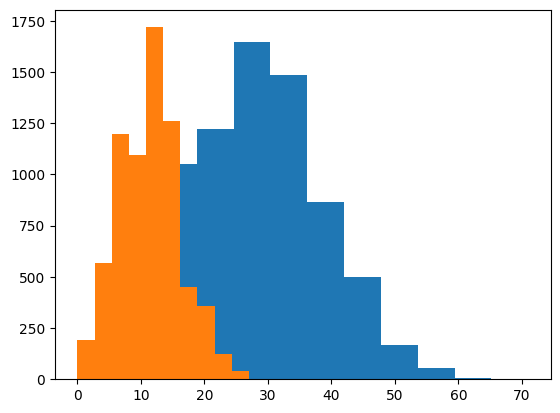

In [26]:
plt.hist(data['age'])
plt.hist(data['anxiety_score_0to27'])

In [27]:
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OrdinalEncoder(), ['gender', 'occupation', 'region', 'most_used_platform', 'night_time_use', 'uses_screen_time_limits', 'attempted_digital_detox', 'seeks_mental_health_support', 'primary_purpose']),
        # ('cat', OrdinalEncoder(), ['gender', 'occupation', 'region', 'most_used_platform', 'night_time_use', 'uses_screen_time_limits', 'attempted_digital_detox', 'seeks_mental_health_support', 'wellbeing_band', 'primary_purpose']),
    ],
    remainder='passthrough' # Options: 'drop' or 'passthrough'
)

In [28]:
data_pre = preprocessor.fit_transform(data)

In [29]:
input = SimpleImputer(strategy='most_frequent')

In [30]:
data_pre = input.fit_transform(data_pre)

In [31]:
preprocessor.get_feature_names_out()

array(['cat__gender', 'cat__occupation', 'cat__region',
       'cat__most_used_platform', 'cat__night_time_use',
       'cat__uses_screen_time_limits', 'cat__attempted_digital_detox',
       'cat__seeks_mental_health_support', 'cat__primary_purpose',
       'remainder__age', 'remainder__platforms_used_count',
       'remainder__daily_screen_hours', 'remainder__daily_notifications',
       'remainder__minutes_to_first_check_after_waking',
       'remainder__avg_sleep_hours', 'remainder__anxiety_score_0to27',
       'remainder__low_mood_score_0to27',
       'remainder__life_satisfaction_1to10',
       'remainder__loneliness_1to10', 'remainder__self_esteem_1to10',
       'remainder__fomo_1to10', 'remainder__social_comparison_1to10',
       'remainder__physical_activity_days_per_week',
       'remainder__wellbeing_band'], dtype=object)

In [32]:
data_pre = pd.DataFrame(data_pre, columns=preprocessor.get_feature_names_out())
data_pre

,cat__gender,cat__occupation,cat__region,cat__most_used_platform,cat__night_time_use,cat__uses_screen_time_limits,cat__attempted_digital_detox,cat__seeks_mental_health_support,cat__primary_purpose,remainder__age,...,remainder__avg_sleep_hours,remainder__anxiety_score_0to27,remainder__low_mood_score_0to27,remainder__life_satisfaction_1to10,remainder__loneliness_1to10,remainder__self_esteem_1to10,remainder__fomo_1to10,remainder__social_comparison_1to10,remainder__physical_activity_days_per_week,remainder__wellbeing_band
0,1.0,4.0,3.0,5.0,1.0,0.0,0.0,1.0,2.0,33,...,8.7,17,0,9,6,4,6,8,4,At-risk
1,0.0,0.0,5.0,1.0,2.0,0.0,1.0,2.0,2.0,23,...,7.3,18,2,7,5,8,5,8,4,At-risk
2,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,2.0,56,...,7.0,12,6,8,7,3,2,3,5,Moderate
3,1.0,4.0,2.0,7.0,3.0,0.0,1.0,2.0,3.0,13,...,7.0,13,0,10,6,6,1,5,4,Moderate
4,0.0,4.0,1.0,2.0,1.0,1.0,2.0,1.0,5.0,36,...,6.7,15,1,4,6,8,7,9,3,Moderate
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6995,1.0,1.0,2.0,4.0,1.0,1.0,0.0,1.0,2.0,30,...,5.9,2,8,4,4,6,3,10,2,Good
6996,1.0,3.0,4.0,0.0,0.0,0.0,1.0,1.0,4.0,28,...,5.8,13,0,8,1,7,6,7,1,Moderate
6997,3.0,5.0,5.0,2.0,1.0,0.0,0.0,1.0,0.0,26,...,8.6,8,9,9,4,5,1,6,3,Good
6998,0.0,4.0,2.0,4.0,3.0,0.0,1.0,1.0,4.0,22,...,7.3,9,4,5,7,4,1,6,2,Good


In [33]:
X = data_pre.drop('remainder__wellbeing_band', axis=1)
y = data_pre['remainder__wellbeing_band']

In [34]:
data_pre = minmax_scale(X)

In [35]:
preprocessor.get_feature_names_out()

array(['cat__gender', 'cat__occupation', 'cat__region',
       'cat__most_used_platform', 'cat__night_time_use',
       'cat__uses_screen_time_limits', 'cat__attempted_digital_detox',
       'cat__seeks_mental_health_support', 'cat__primary_purpose',
       'remainder__age', 'remainder__platforms_used_count',
       'remainder__daily_screen_hours', 'remainder__daily_notifications',
       'remainder__minutes_to_first_check_after_waking',
       'remainder__avg_sleep_hours', 'remainder__anxiety_score_0to27',
       'remainder__low_mood_score_0to27',
       'remainder__life_satisfaction_1to10',
       'remainder__loneliness_1to10', 'remainder__self_esteem_1to10',
       'remainder__fomo_1to10', 'remainder__social_comparison_1to10',
       'remainder__physical_activity_days_per_week',
       'remainder__wellbeing_band'], dtype=object)

In [36]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## select model

In [37]:
svm = SVC()
gau = GaussianNB()
knn = KNeighborsClassifier()
dtc = DecisionTreeClassifier()
rfc = RandomForestClassifier()
gbc = GradientBoostingClassifier()
abc = AdaBoostClassifier()
mlp = MLPClassifier()

In [38]:
for i in [svm, gau, knn, dtc, rfc, gbc, abc, mlp]:
  i.fit(X_train, y_train)
  print(f"{i} - {i.score(X_test, y_test)}")

SVC() - 0.8657142857142858
GaussianNB() - 0.8478571428571429
KNeighborsClassifier() - 0.7585714285714286
DecisionTreeClassifier() - 1.0
RandomForestClassifier() - 0.9992857142857143
GradientBoostingClassifier() - 1.0
AdaBoostClassifier() - 0.9578571428571429
MLPClassifier() - 0.9192857142857143


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


In [39]:
# cross = cross_val_score(rfc, X, y, cv=4)
# cross

In [40]:
param_grid_knn = [{
    "n_neighbors":[1,3,5,7],
    "weights":["uniform", "distance"],
    "leaf_size":[10,20,50]
    # "algorithm":["auto", "ball_tree", "kd_tree", "brute"]
}]

In [41]:
# grid_seach = GridSearchCV(knn, param_grid_knn, cv=4, return_train_score=True, verbose=10, scoring="accuracy")
# grid_seach.fit(X, y)

In [42]:
# final_knn = grid_seach.best_estimator_
# final_knn

In [43]:
# final_knn.score(X_test, y_test)

In [44]:
param_grid_svm = [{
    "C":[60,100],
    "kernel":["poly", "rbf", "sigmoid"],
    # "degree":[1,3,5],
    # "gamma":["auto", "scale"]
}]

In [45]:
# grid_seach = GridSearchCV(svm, param_grid_svm, cv=4, return_train_score=True, verbose=10, scoring="accuracy")
# grid_seach.fit(X, y)

In [46]:
# final_svm = grid_seach.best_estimator_
# final_svm

In [47]:
# final_svm.score(X_test, y_test)

In [48]:
param_grid_gau = [{
    # "priors":[1, 10,20,30,50,100,200],
    "var_smoothing":[1e-09, 1e-10, 1e-11, 1, 10]
}]

In [49]:
# grid_seach = GridSearchCV(gau, param_grid_gau, cv=4, return_train_score=True, verbose=10, scoring="accuracy", error_score='raise')
# grid_seach.fit(X, y)

In [50]:
# final_gau = grid_seach.best_estimator_
# final_gau

In [51]:
# final_gau.score(X_test, y_test)

In [52]:
param_grid_dtc = [{
    "criterion":["gini","entropy","log_loss"],
    "splitter":["best", "random"],
    "max_depth":[10,20,30],
}]

In [53]:
# grid_seach = GridSearchCV(dtc, param_grid_dtc, cv=4, return_train_score=True, verbose=10, scoring="accuracy", error_score='raise')
# grid_seach.fit(X, y)

In [54]:
# final_dtc = grid_seach.best_estimator_
# final_dtc

In [55]:
# final_dtc.score(X_test, y_test)

In [56]:
param_grid_rfc = [{
    "n_estimators":[1,500],
    "criterion":["gini","entropy","log_loss"],
    "max_depth":[10,50],
}]

In [57]:
# grid_seach = GridSearchCV(rfc, param_grid_rfc, cv=4, return_train_score=True, verbose=10, scoring="accuracy", error_score='raise')
# grid_seach.fit(X, y)

In [58]:
# final_rfc = grid_seach.best_estimator_
# final_rfc

In [59]:
# final_rfc.score(X_test, y_test)

In [60]:
param_grid_gbc = [{
    "n_estimators":[10,50],
    # "loss":["log_loss","exponential"],
    "learning_rate":[0.5, 0.1],
}]

In [61]:
# grid_seach = GridSearchCV(gbc, param_grid_gbc, cv=4, return_train_score=True, verbose=10, scoring="accuracy", error_score='raise')
# grid_seach.fit(X, y)

In [62]:
# final_gbc = grid_seach.best_estimator_
# final_gbc

In [63]:
# final_gbc.score(X_test, y_test)

In [64]:
param_grid_abc = [{
    "n_estimators":[5, 10],
    # "loss":["log_loss","exponential"],
    "learning_rate":[0.5, 0.1],
}]

In [65]:
# grid_seach = GridSearchCV(abc, param_grid_abc, cv=4, return_train_score=True, verbose=10, scoring="accuracy", error_score='raise')
# grid_seach.fit(X, y)

In [66]:
# final_abc = grid_seach.best_estimator_
# final_abc

In [67]:
# final_abc.score(X_test, y_test)

In [68]:
param_grid_mlp = [{
    "hidden_layer_sizes":[5, 10, 50],
    "activation":["identity","logistic", "tanh","relu"],
    # "solver":["lbfgs","sgd", "adam"],
    "learning_rate_init":[0.01, 0.5],
}]

In [69]:
# grid_seach = GridSearchCV(mlp, param_grid_mlp, cv=4, return_train_score=True, verbose=10, scoring="accuracy", error_score='raise')
# grid_seach.fit(X, y)

In [70]:
# final_mlp = grid_seach.best_estimator_
# final_mlp

In [71]:
# final_mlp.score(X_test, y_test)

## new date

In [72]:
from sklearn.model_selection import train_test_split
import pandas as pd

In [73]:
data = pd.read_csv("/content/social_media_screentime_mental_health_2026.csv")
data = data.drop('participant_id', axis=1)
data

,age,gender,occupation,region,most_used_platform,platforms_used_count,daily_screen_hours,daily_notifications,night_time_use,minutes_to_first_check_after_waking,...,life_satisfaction_1to10,loneliness_1to10,self_esteem_1to10,fomo_1to10,social_comparison_1to10,physical_activity_days_per_week,uses_screen_time_limits,attempted_digital_detox,seeks_mental_health_support,wellbeing_band
0,33,Male,Student,Latin America,TikTok,8,3.2,172,Never,25,...,9,6,4,6,8,4,No,No,No,At-risk
1,23,Female,Full-time employed,Oceania,Instagram,8,4.5,38,Often,26,...,7,5,8,5,8,4,No,"Yes, failed",Yes,At-risk
2,56,Female,Full-time employed,Africa,Instagram,1,5.3,74,Every night,12,...,8,7,3,2,3,5,No,No,No,Moderate
3,13,Male,Student,Europe,YouTube,4,3.4,49,Sometimes,21,...,10,6,6,1,5,4,No,"Yes, failed",Yes,Moderate
4,36,Female,Student,Asia,LinkedIn,5,5.8,227,Never,19,...,4,6,8,7,9,3,Yes,"Yes, succeeded",No,Moderate
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6995,30,Male,Part-time employed,Europe,Snapchat,4,3.6,74,Never,7,...,4,4,6,3,10,2,Yes,No,No,Good
6996,28,Male,Self-employed,North America,Facebook,3,5.0,104,Every night,48,...,8,1,7,6,7,1,No,"Yes, failed",No,Moderate
6997,26,Prefer not to say,Unemployed,Oceania,LinkedIn,3,1.2,25,Never,6,...,9,4,5,1,6,3,No,No,No,Good
6998,22,Female,Student,Europe,Snapchat,4,3.6,182,Sometimes,12,...,5,7,4,1,6,2,No,"Yes, failed",No,Good


In [74]:
X = data.drop('wellbeing_band', axis=1)
y = data['wellbeing_band']

In [75]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## pipeline

In [76]:
pipeline_mode = Pipeline([
    ('one_hot_encoder', OneHotEncoder(handle_unknown='ignore')),
    ('normalizer', Normalizer()),
    ('simpleImputer', SimpleImputer()),
    ('classifier', DecisionTreeClassifier()),
])
pipeline_mode

Pipeline(steps=[('one_hot_encoder', OneHotEncoder(handle_unknown='ignore')),
                ('normalizer', Normalizer()),
                ('simpleImputer', SimpleImputer()),
                ('classifier', DecisionTreeClassifier())])

In [77]:
pipeline_mode.fit(X_train, y_train)

Pipeline(steps=[('one_hot_encoder', OneHotEncoder(handle_unknown='ignore')),
                ('normalizer', Normalizer()),
                ('simpleImputer', SimpleImputer()),
                ('classifier', DecisionTreeClassifier())])

In [78]:
pipeline_mode.score(X_test, y_test)

0.9942857142857143

## save classification

In [79]:
import joblib

In [80]:
# Salvando o modelo treinado em um arquivo
joblib.dump(pipeline_mode, "classificador.pkl")

['classificador.pkl']

In [81]:
# Carregando o modelo de volta
clf_carregado = joblib.load("classificador.pkl")

In [82]:
clf_carregado.score(X_test, y_test)

0.9942857142857143

## testa classsificador

In [83]:
import joblib
from sklearn.model_selection import train_test_split
import pandas as pd

In [84]:
# Carregando o modelo de volta
clf_carregado = joblib.load("classificador.pkl")

In [85]:
data = pd.read_csv("/content/social_media_screentime_mental_health_2026.csv")
data = data.drop('participant_id', axis=1)
data

,age,gender,occupation,region,most_used_platform,platforms_used_count,daily_screen_hours,daily_notifications,night_time_use,minutes_to_first_check_after_waking,...,life_satisfaction_1to10,loneliness_1to10,self_esteem_1to10,fomo_1to10,social_comparison_1to10,physical_activity_days_per_week,uses_screen_time_limits,attempted_digital_detox,seeks_mental_health_support,wellbeing_band
0,33,Male,Student,Latin America,TikTok,8,3.2,172,Never,25,...,9,6,4,6,8,4,No,No,No,At-risk
1,23,Female,Full-time employed,Oceania,Instagram,8,4.5,38,Often,26,...,7,5,8,5,8,4,No,"Yes, failed",Yes,At-risk
2,56,Female,Full-time employed,Africa,Instagram,1,5.3,74,Every night,12,...,8,7,3,2,3,5,No,No,No,Moderate
3,13,Male,Student,Europe,YouTube,4,3.4,49,Sometimes,21,...,10,6,6,1,5,4,No,"Yes, failed",Yes,Moderate
4,36,Female,Student,Asia,LinkedIn,5,5.8,227,Never,19,...,4,6,8,7,9,3,Yes,"Yes, succeeded",No,Moderate
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6995,30,Male,Part-time employed,Europe,Snapchat,4,3.6,74,Never,7,...,4,4,6,3,10,2,Yes,No,No,Good
6996,28,Male,Self-employed,North America,Facebook,3,5.0,104,Every night,48,...,8,1,7,6,7,1,No,"Yes, failed",No,Moderate
6997,26,Prefer not to say,Unemployed,Oceania,LinkedIn,3,1.2,25,Never,6,...,9,4,5,1,6,3,No,No,No,Good
6998,22,Female,Student,Europe,Snapchat,4,3.6,182,Sometimes,12,...,5,7,4,1,6,2,No,"Yes, failed",No,Good


In [86]:
X = data.drop('wellbeing_band', axis=1)
y = data['wellbeing_band']

In [87]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [88]:
clf_carregado.score(X_test, y_test)

0.9942857142857143

## metrics

In [89]:
# y_pred = rfc.predict(X_test)
y_pred = pipeline_mode.predict(X_test)
y_pred

array(['Good', 'Good', 'Moderate', ..., 'Good', 'Moderate', 'At-risk'],
      dtype=object)

In [90]:
accuracy_score(y_test, y_pred)

0.9942857142857143

In [91]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

     At-risk       1.00      0.99      1.00       188
        Good       0.98      1.00      0.99       458
    Moderate       1.00      0.99      1.00       754

    accuracy                           0.99      1400
   macro avg       0.99      1.00      0.99      1400
weighted avg       0.99      0.99      0.99      1400



In [92]:
confusion_matrix(y_test, y_pred)

array([[187,   1,   0],
       [  0, 458,   0],
       [  0,   7, 747]])

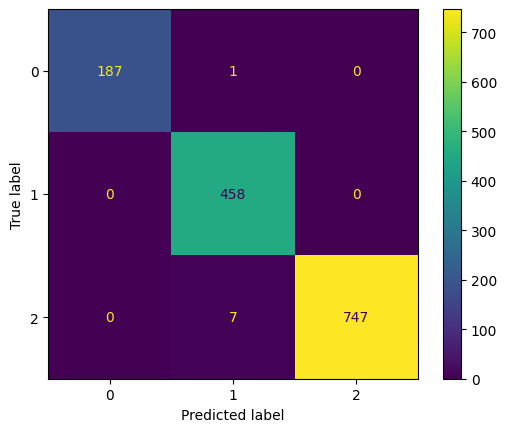

In [93]:
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot()

In [94]:
f1_score(y_test, y_pred, average='weighted')

0.9942978401782856

In [95]:
precision_score(y_test, y_pred, average='macro')

0.9942775393419171

In [96]:
recall_score(y_test, y_pred, average='macro')

0.9951323438117275